# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Raihan Nurhakim | 5054251030 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [56]:
# Import library yang dibutuhkan.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [57]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.
df = pd.read_csv("insurance.csv")


In [58]:
# Tampilkan beberapa baris pertama dataset.
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [59]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [60]:
# Periksa missing value.
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [61]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [62]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())



sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


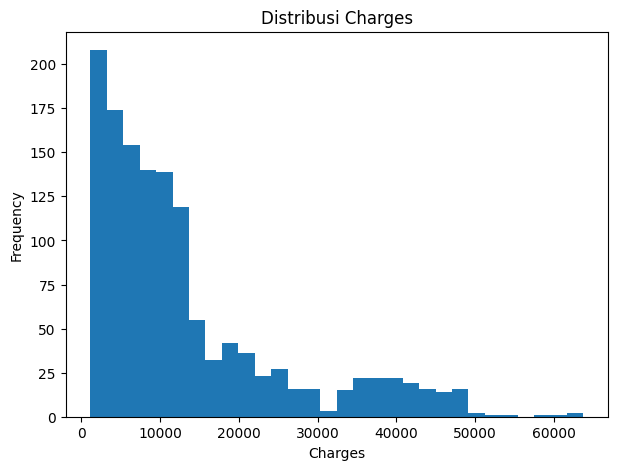

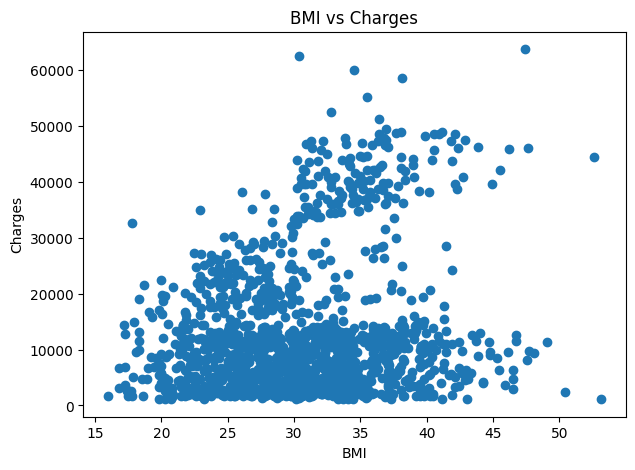

In [63]:
plt.figure(figsize=(7, 5))
plt.hist(df["charges"], bins=30)
plt.title("Distribusi Charges")
plt.xlabel("Charges")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(df["bmi"], df["charges"])
plt.title("BMI vs Charges")
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.show()


## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [64]:
# Pisahkan fitur (X) dan target (y).
X = df.drop("charges", axis=1)
y = df["charges"]

In [65]:
# Identifikasi kolom numerik dan kategorikal.
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Kolom numerik:", numeric_cols)
print("Kolom kategorikal:", categorical_cols)

Kolom numerik: ['age', 'bmi', 'children']
Kolom kategorikal: ['sex', 'smoker', 'region']


In [66]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (1070, 6)
X_test: (268, 6)


In [67]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocessor_scaled = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

preprocessor_tree = ColumnTransformer(transformers=[
    ("num", "passthrough", numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])


# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [68]:
# Inisialisasi dan latih Linear Regression.
linear_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('model', LinearRegression())])

In [69]:
# Lakukan prediksi pada test set.
y_pred_linear = linear_model.predict(X_test)

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [70]:
# Buat fitur polynomial dan latih model.
polynomial_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", Ridge(alpha=1.0))
])

polynomial_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('polynomial', PolynomialFeatures(include_bias=False)),
                ('model', Ridge())])

In [71]:
# Lakukan prediksi pada test set.
y_pred_polynomial = polynomial_model.predict(X_test)

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [72]:
# Inisialisasi dan latih Ridge Regression.
ridge_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", Ridge(alpha=10.0))
])

ridge_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('model', Ridge(alpha=10.0))])

In [73]:
# Lakukan prediksi pada test set.
y_pred_ridge = ridge_model.predict(X_test)


## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [74]:
# Inisialisasi dan latih Lasso Regression.
lasso_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", Lasso(alpha=10.0, max_iter=10000))
])

lasso_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('model', Lasso(alpha=10.0, max_iter=10000))])

In [75]:
# Lakukan prediksi pada test set.
y_pred_lasso = lasso_model.predict(X_test)


## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [76]:
# Inisialisasi dan latih Decision Tree Regressor.
tree_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42))
])

tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('model',
                 DecisionTreeRegressor(max_depth=5, min_samples_leaf=5,
                                       random_state=42))])

In [77]:
# Lakukan prediksi pada test set.
y_pred_tree = tree_model.predict(X_test)

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [78]:
# Inisialisasi dan latih SVR.
svr_model = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("model", SVR(kernel="rbf", C=100, epsilon=0.1))
])

svr_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('model', SVR(C=100))])

In [79]:
# Lakukan prediksi pada test set.
y_pred_svr = svr_model.predict(X_test)

# 4. Evaluasi Model

In [80]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
predictions = {
    "Linear Regression": y_pred_linear,
    "Polynomial Regression": y_pred_polynomial,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso,
    "Decision Tree": y_pred_tree,
    "SVR": y_pred_svr
}

results = []

for model_name, predictions_model in predictions.items():
    mae = mean_absolute_error(y_test, predictions_model)
    mse = mean_squared_error(y_test, predictions_model)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions_model)

    results.append([model_name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R²"]
)

results_df.sort_values("RMSE")

,Model,MAE,MSE,RMSE,R²
4,Decision Tree,2647.216443,2.035881e+07,4512.074159,0.868863
1,Polynomial Regression,2732.787487,2.070505e+07,4550.280414,0.866633
0,Linear Regression,4181.194474,3.359692e+07,5796.284659,0.783593
3,Lasso Regression,4189.394273,3.368343e+07,5803.742871,0.783036
2,Ridge Regression,4238.823917,3.389093e+07,5821.591697,0.781699
5,SVR,5967.493094,1.339913e+08,11575.461958,0.136925


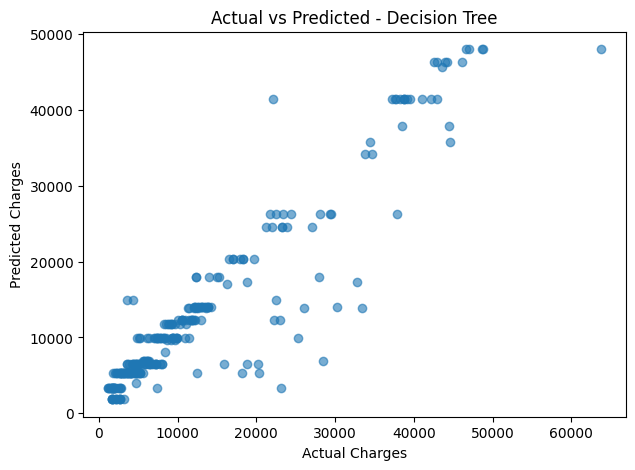

In [81]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
best_model = results_df.loc[results_df["RMSE"].idxmin(), "Model"]
best_predictions = predictions[best_model]

plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_predictions, alpha=0.6)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title(f"Actual vs Predicted - {best_model}")
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.


Berdasarkan tabel evaluasi, model dibandingkan menggunakan MAE, MSE, RMSE, dan R². MAE, MSE, dan RMSE yang lebih kecil menunjukkan prediksi yang lebih baik, sedangkan R² yang lebih besar menunjukkan kemampuan model menjelaskan variasi target yang lebih baik.

Fitur numerik pada Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan scaling agar skala antarfitur lebih seimbang. Fitur kategorikal diubah menjadi numerik menggunakan OneHotEncoder. Decision Tree tidak menggunakan scaling karena model berbasis aturan pemisahan data.

Polynomial Regression menggunakan degree 2 untuk menangkap hubungan non-linear sederhana. Ridge dan Lasso menggunakan regularisasi untuk membantu mengurangi pengaruh koefisien yang terlalu besar. Decision Tree menggunakan `max_depth=5` dan `min_samples_leaf=5` untuk menjaga model agar tidak terlalu kompleks. SVR menggunakan kernel RBF dengan `C=100`.

Model terbaik dapat dilihat dari nilai RMSE terkecil dan R² terbesar pada tabel hasil.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.


Berdasarkan hasil eksperimen, model dengan nilai RMSE paling kecil dan R² paling besar dapat dipilih sebagai model terbaik untuk memprediksi `charges`. Perbedaan hasil antar-model menunjukkan bahwa pemilihan preprocessing dan parameter berpengaruh terhadap kemampuan model dalam melakukan prediksi.

Untuk pengembangan lebih lanjut, parameter model dapat dituning menggunakan GridSearchCV atau RandomizedSearchCV. Selain itu, dapat dilakukan eksperimen dengan metode preprocessing atau model regresi lain untuk memperoleh hasil yang lebih baik.